In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import pickle as p

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.inspection import permutation_importance

In [84]:
dataset = pd.read_csv('../data/heart_failure/heart_failure_clinical_records_dataset.csv')
dataset.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [97]:
dataset.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='str')

In [85]:
features = dataset.drop('DEATH_EVENT', axis=1)
targets = dataset['DEATH_EVENT']

features_trainval, features_test, targets_trainval, targets_test = \
    train_test_split(features, targets, test_size=0.2, stratify=targets)

In [86]:
features_normalized_trainval = (features_trainval - features_trainval.mean())/features_trainval.std()
features_normalized_test = (features_test - features_trainval.mean())/features_trainval.std()

In [98]:
features_normalized_test.iloc[0]


age                         0.970798
anaemia                     1.156511
creatinine_phosphokinase   -0.520295
diabetes                   -0.861052
ejection_fraction          -1.104289
high_blood_pressure        -0.734621
platelets                   0.051001
serum_creatinine           -0.361847
serum_sodium                0.770517
sex                         0.741376
smoking                     1.447444
time                       -0.872430
Name: 67, dtype: float64

In [87]:
def test(model):
    predictions_train = model.predict(features_normalized_trainval)
    predictions_test = model.predict(features_normalized_test)
    precision_train = precision_score(targets_trainval, predictions_train)
    recall_train = recall_score(targets_trainval, predictions_train)
    precision_test = precision_score(targets_test, predictions_test)
    recall_test = recall_score(targets_test, predictions_test)
    print(f'Train Precision: {precision_train:.3f} Recall: {recall_train:.3f}')
    print(f'Test Precision: {precision_test:.3f} Recall: {recall_test:.3f}')

Train Precision: 0.740 Recall: 0.481
Test Precision: 0.706 Recall: 0.632


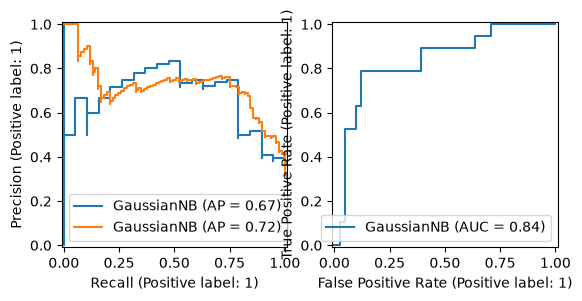

In [88]:
nb1 = GaussianNB()
nb1.fit(features_normalized_trainval, targets_trainval)
test(nb1)
fig, ax = plt.subplots(1, 2)
PrecisionRecallDisplay.from_estimator(nb1, features_normalized_test, targets_test, ax=ax[0])
PrecisionRecallDisplay.from_estimator(nb1, features_normalized_trainval, targets_trainval, ax=ax[0])
RocCurveDisplay.from_estimator(nb1, features_normalized_test, targets_test, ax=ax[1])

Train Precision: 1.000 Recall: 1.000
Test Precision: 0.682 Recall: 0.789


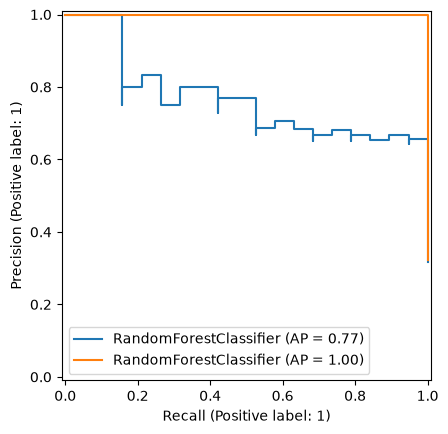

In [90]:
rf1 = RandomForestClassifier()
rf1.fit(features_normalized_trainval, targets_trainval)
test(rf1)
fig, ax = plt.subplots(1,1)
PrecisionRecallDisplay.from_estimator(rf1, features_normalized_test, targets_test, ax=ax)
PrecisionRecallDisplay.from_estimator(rf1, features_normalized_trainval,targets_trainval, ax=ax)

In [91]:
predictions =  rf1.predict_proba(features_normalized_trainval)
unique_probs = np.unique(predictions[:,1])
for threshold in unique_probs:
    predictions_ = (predictions[:,1]>=threshold)*1
    precision = precision_score(targets_trainval, predictions_)
    recall = recall_score(targets_trainval, predictions_)
    print(f'Threshold: {threshold} precision {precision} recall {recall}')

Threshold: 0.0 precision 0.32217573221757323 recall 1.0
Threshold: 0.01 precision 0.3515981735159817 recall 1.0
Threshold: 0.02 precision 0.385 recall 1.0
Threshold: 0.03 precision 0.4350282485875706 recall 1.0
Threshold: 0.04 precision 0.4723926380368098 recall 1.0
Threshold: 0.05 precision 0.5238095238095238 recall 1.0
Threshold: 0.06 precision 0.5703703703703704 recall 1.0
Threshold: 0.07 precision 0.6015625 recall 1.0
Threshold: 0.08 precision 0.6062992125984252 recall 1.0
Threshold: 0.09 precision 0.6363636363636364 recall 1.0
Threshold: 0.1 precision 0.6470588235294118 recall 1.0
Threshold: 0.11 precision 0.6875 recall 1.0
Threshold: 0.12 precision 0.7333333333333333 recall 1.0
Threshold: 0.14 precision 0.7623762376237624 recall 1.0
Threshold: 0.15 precision 0.7857142857142857 recall 1.0
Threshold: 0.16 precision 0.8279569892473119 recall 1.0
Threshold: 0.17 precision 0.8369565217391305 recall 1.0
Threshold: 0.18 precision 0.8555555555555555 recall 1.0
Threshold: 0.19 precision 0

In [92]:
class ThresholdClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator, threshold=0.5):
        self.estimator = estimator
        self.threshold = threshold

    def fit(self, x, y):
        if hasattr(self.estimator, 'classes_'):
            self.classes_ = self.estimator.classes_
            return self
        self.estimator.fit(x,y)
        return self

    def predict(self, x):
        probabilities = self.predict_proba(x)
        return (probabilities[:,1]>=threshold).astype(int)

    def predict_proba(self, x):
        return self.estimator.predict_proba(x)
        

In [93]:
rft1 = ThresholdClassifier(rf1, threshold=0.62)
test(rft1)

Train Precision: 1.000 Recall: 0.013
Test Precision: 0.000 Recall: 0.000


/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [96]:
with (open('rf1.pickle', 'wb') as f):
    p.dump(rf1, f)

In [ ]:
results = permutation_importance(rf1, features_normalized_trainval, targets_trainval)
# sb.barplot(data=pd.DataFrame({'mean':results.importances_mean}), x='mean')
# importances = pd.DataFrame(results.importances, index=features.columns, columns=range(5))
# importances = importances.reset_index()
# sb.barplot(data=importances, y='index')

TypeError: bar() missing 1 required positional argument: 'height'